# ECSE 552 — Assignment 2, Part 3: Weather Forecasting (Local Version)

**Group 5 — Complete, corrected notebook for running locally**

This notebook keeps the local CSV-loading approach from our original notebook and provides the full pipeline: data cleaning, hourly sampling, chronological train/validation/test split, sliding windows, training three neural networks (fully connected, LSTM, RNN), per-attribute comparisons, and recursive error-propagation analysis.

**Local data setup (same as original):** Put the course CSV file(s) matching `jena*.csv*` inside a folder named **`sample_data`**, relative to the notebook's working directory:

```text
project_folder/
├── ECSE552_W25_Assignment2_Part3_Group5_LOCAL.ipynb
└── sample_data/
    └── jena_climate_2009_2016.csv
```

The loading code searches with `glob.glob(os.path.join(DATA_DIR, "jena*.csv*"))`, reads any matching CSV files, concatenates them, parses timestamps, sorts them, and removes duplicate dates — as in the original notebook. No internet connection or automatic download is needed.

**Run:** `Kernel → Restart Kernel and Run All Cells` (or the equivalent in VS Code/Jupyter). The notebook defaults to `K = 4`, two hidden/recurrent layers per model, and `2009–2014 / 2015 / 2016` chronological splits. The data must cover these years to support the assignment's evaluation.


## 1. Imports and experiment settings

In [1]:
import glob
import os
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Imports
# os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
if not torch.cuda.is_available():
    torch.set_num_threads(min(4, torch.get_num_threads()))

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TARGET_COLS = ['p (mbar)', 'T (degC)', 'rh (%)', 'wv (m/s)']
K = 4                   # Assignment specifies k in [4, 8]
HIDDEN_SIZE = 32
NUM_LAYERS = 2          # Same number of hidden/recurrent layers for every model
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
MAX_EPOCHS = 25
PATIENCE = 5
HORIZON = 24

assert 4 <= K <= 8
assert MAX_EPOCHS > 0 and PATIENCE > 0 and HORIZON > 0
print(f'PyTorch {torch.__version__} | device: {DEVICE} | k={K} | batch={BATCH_SIZE}')


PyTorch 2.10.0 | device: cpu | k=4 | batch=256


## 2. Load local data (same folder and glob pattern as the original notebook)

The course dataset must already be stored under `sample_data/`. Multiple matching `jena*.csv*` files are supported (as in the original), and any duplicate timestamps are removed. **This notebook never downloads data.**


In [2]:
# Same local directory/pattern as the original Group 5 notebook.
DATA_DIR = 'sample_data'
files = sorted(glob.glob(os.path.join(DATA_DIR, 'jena*.csv*')))

print(len(files), 'files found:')
for f in files:
    print(' ', os.path.basename(f))

if not files:
    raise FileNotFoundError(
        f'No jena*.csv* files found in {os.path.abspath(DATA_DIR)!r}. '
        'Put the course Jena CSV file(s) inside sample_data/ next to your notebook, '
        'or change DATA_DIR above to the directory containing those files.'
    )

# Inspect the first file, following the original notebook.
sample = pd.read_csv(files[0], low_memory=False)
print('First file shape:', sample.shape)
print('First file columns:', sample.columns.tolist())

# Load and concatenate all local CSV files.
dfs = []
for file_path in files:
    part = pd.read_csv(file_path, low_memory=False)
    part['source_file'] = os.path.basename(file_path)
    dfs.append(part)

raw = pd.concat(dfs, ignore_index=True)
missing_cols = [col for col in ['Date Time', *TARGET_COLS] if col not in raw.columns]
if missing_cols:
    raise ValueError(f'Missing required columns: {missing_cols}')

# Parse, sort, and deduplicate timestamps exactly as in the original approach.
raw['Date Time'] = pd.to_datetime(
    raw['Date Time'], format='%d.%m.%Y %H:%M:%S', errors='coerce'
)
invalid_dates = int(raw['Date Time'].isna().sum())
raw = raw.dropna(subset=['Date Time']).sort_values('Date Time', kind='stable')
raw_duplicates = int(raw['Date Time'].duplicated().sum())
raw = raw.drop_duplicates(subset='Date Time', keep='first').reset_index(drop=True)

print(f'Rows after removing duplicate/unparseable timestamps: {len(raw):,}')
print(f'Duplicate timestamps removed: {raw_duplicates:,}')
print(f'Unparseable timestamps removed: {invalid_dates:,}')
print(f'Date range: {raw["Date Time"].min()} -> {raw["Date Time"].max()}')
assert len(raw) > 100, 'Dataset is unexpectedly small; check local CSV files.'


1 files found:
  jena_climate_2009_2016.csv
First file shape: (420551, 15)
First file columns: ['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']
Rows after removing duplicate/unparseable timestamps: 420,224
Duplicate timestamps removed: 327
Unparseable timestamps removed: 0
Date range: 2009-01-01 00:10:00 -> 2017-01-01 00:00:00


## 3. Hourly sampling, data cleaning and continuity

The TA instruction recorded in the original notebook is to **keep every sixth record, beginning at 2009-01-01 01:00**. We use this rule when the input is the original 10-minute CSV. If the course provides an already-hourly file, we do **not** downsample it again.

Some readings are missing or timestamps have gaps. We assign a new *segment* whenever two consecutive retained records are not exactly one hour apart. Every feature window and multi-step forecast is required to remain within a single continuous segment.

For missing input values, we use **past-only forward filling within a segment**. We *do not* train/evaluate against imputed labels. The single pressure outlier noted in the group's original inspection is corrected **only in the pressure column** (when present).

In [3]:
median_step = raw['Date Time'].diff().median()
anchor = pd.Timestamp('2009-01-01 01:00:00')

if median_step <= pd.Timedelta(minutes=20):
    matches = np.flatnonzero((raw['Date Time'] == anchor).to_numpy())
    if len(matches) == 0:
        raise ValueError(f'Hourly anchor {anchor} missing from 10-minute CSV.')
    df = raw.iloc[int(matches[0])::6].copy().reset_index(drop=True)
    print('Original ~10-minute data detected; retained every sixth row from 01:00.')
elif pd.Timedelta(minutes=50) <= median_step <= pd.Timedelta(minutes=70):
    df = raw[raw['Date Time'] >= anchor].copy().reset_index(drop=True)
    print('Already-hourly data detected; did not downsample a second time.')
else:
    raise ValueError(f'Unexpected sampling interval: {median_step}')

# The assignment evaluates 2009–2016. Discard the 2017 boundary record.
df = df[(df['Date Time'].dt.year >= 2009) &
        (df['Date Time'].dt.year <= 2016)].copy().reset_index(drop=True)

for col in TARGET_COLS:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df.loc[df[col] <= -9000, col] = np.nan
# Invalid physically impossible values; keep realistic zero wind speed.
df.loc[df['wv (m/s)'] < 0, 'wv (m/s)'] = np.nan
df.loc[(df['rh (%)'] <= 0) | (df['rh (%)'] > 100), 'rh (%)'] = np.nan
df.loc[df['p (mbar)'] <= 0, 'p (mbar)'] = np.nan

# Outlier identified by Group 5's original inspection (2011-06-06 13:20).
bad_pressure = ((df['Date Time'] == pd.Timestamp('2011-06-06 13:20:00')) &
                (df['p (mbar)'] < 930))
print('Known isolated pressure outlier(s) flagged:', int(bad_pressure.sum()))
df.loc[bad_pressure, 'p (mbar)'] = np.nan

step = df['Date Time'].diff()
df['segment'] = step.ne(pd.Timedelta(hours=1)).cumsum()
# Track unmodified ground truth. Never use fabricated target values in the loss/metrics.
df['observed_target'] = df[TARGET_COLS].notna().all(axis=1)
print('Rows with a missing/invalid target before imputing inputs:',
      int((~df['observed_target']).sum()))
df[TARGET_COLS] = df.groupby('segment', sort=False)[TARGET_COLS].ffill()
df['valid_input'] = df[TARGET_COLS].notna().all(axis=1)
df['year'] = df['Date Time'].dt.year

print('Hourly rows:', len(df), '| continuous segments:', df['segment'].nunique())
print('Non-hourly jumps:', int((step.iloc[1:] != pd.Timedelta(hours=1)).sum()))
print('Unfilled first-of-segment input rows:', int((~df['valid_input']).sum()))
print(df[TARGET_COLS].describe().loc[['min', 'mean', 'max']])
assert not df.empty

Original ~10-minute data detected; retained every sixth row from 01:00.
Known isolated pressure outlier(s) flagged: 1
Rows with a missing/invalid target before imputing inputs: 4
Hourly rows: 70037 | continuous segments: 6
Non-hourly jumps: 5
Unfilled first-of-segment input rows: 0
         p (mbar)   T (degC)     rh (%)   wv (m/s)
min    942.650000 -22.760000   13.88000   0.000000
mean   989.214899   9.443924   76.02761   2.127794
max   1015.350000  37.100000  100.00000  14.010000


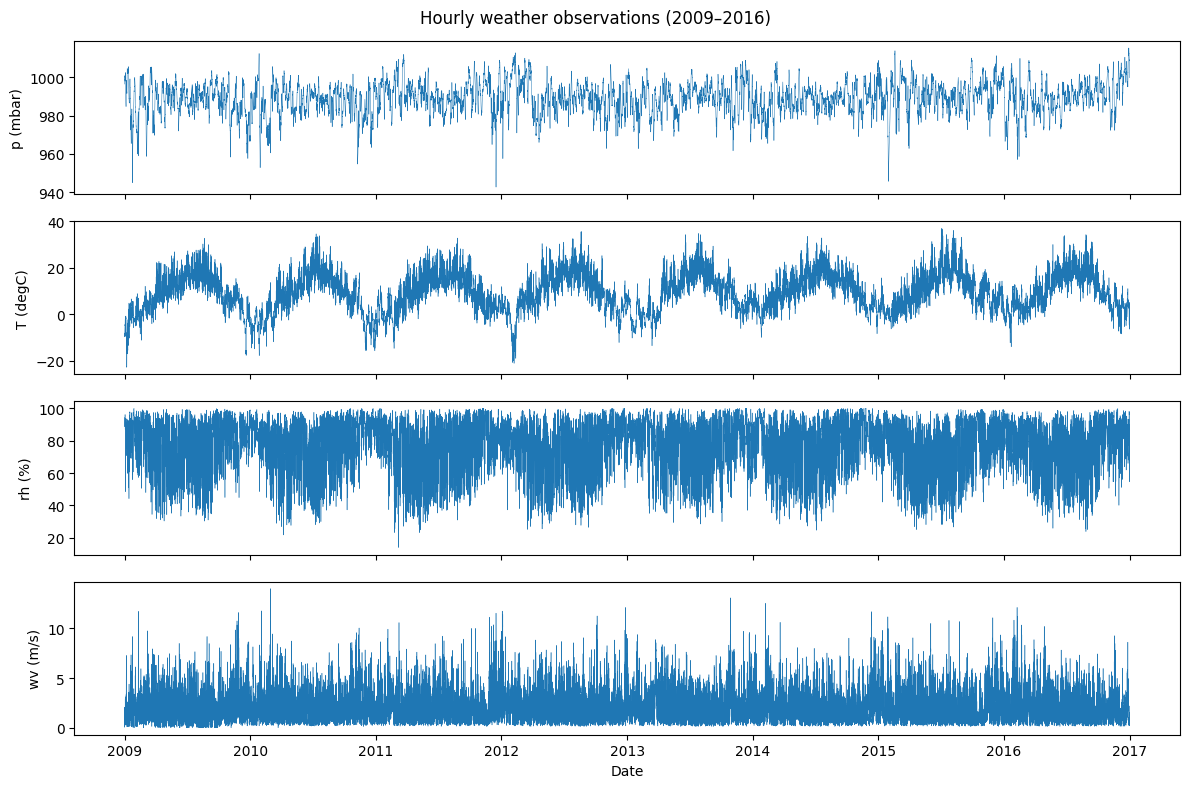

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, TARGET_COLS):
    ax.plot(df['Date Time'], df[col], linewidth=0.35)
    ax.set_ylabel(col)
axes[-1].set_xlabel('Date')
fig.suptitle('Hourly weather observations (2009–2016)')
plt.tight_layout()
plt.show()

## 4. Chronological split and leakage-safe sliding windows

A sample with target at time **t** uses rows **t − K, …, t − 1** as input. We create windows over the full chronology, then assign a window to train/validation/test by the **year of its target**. Thus the earliest validation/test forecasts can legitimately use prior observed hours from the preceding split, without using any future labels.

To prevent leakage: (1) all windows must be from one continuous segment, (2) training statistics are computed on the training years **only**, and (3) test data is never used for early stopping or hyperparameter selection.

In [5]:
values = df[TARGET_COLS].to_numpy(dtype=np.float32)
segment = df['segment'].to_numpy()
valid_input = df['valid_input'].to_numpy(dtype=bool)
observed_target = df['observed_target'].to_numpy(dtype=bool)
years = df['year'].to_numpy()

n = len(df) - K
if n <= 0:
    raise ValueError(f'Not enough records to form K={K} windows')
# Fast/vectorized construction: X[i] contains rows i .. i+K-1; y[i] is i+K.
X_all_raw = np.stack([values[offset:offset+n] for offset in range(K)], axis=1)
y_all_raw = values[K:]
target_indices = np.arange(K, len(df))

input_ok = np.logical_and.reduce(
    [valid_input[offset:offset+n] for offset in range(K)]
)
continuous = segment[:n] == segment[K:]
window_ok = input_ok & observed_target[K:] & continuous
X_all_raw = X_all_raw[window_ok]
y_all_raw = y_all_raw[window_ok]
target_indices = target_indices[window_ok]
window_years = years[target_indices]

split_masks = {
    'train': (window_years <= 2014),
    'val': (window_years == 2015),
    'test': (window_years == 2016),
}
for split_name, mask in split_masks.items():
    print(f'{split_name:5}: {int(mask.sum()):,} prediction windows')
    assert mask.any(), f'No windows in {split_name}. Check the year coverage of the CSV.'
print('X shape:', X_all_raw.shape, '| y shape:', y_all_raw.shape)
assert X_all_raw.shape[1:] == (K, 4)
assert y_all_raw.shape[1:] == (4,)
assert np.isfinite(X_all_raw).all() and np.isfinite(y_all_raw).all()

train: 52,546 prediction windows
val  : 8,757 prediction windows
test : 8,706 prediction windows
X shape: (70009, 4, 4) | y shape: (70009, 4)


## 5. Normalize inputs and targets using **training-only** statistics

In [6]:
train_rows = (df['year'] <= 2014) & df['observed_target']
train_measurements = df.loc[train_rows, TARGET_COLS].to_numpy(dtype=np.float64)
mean = train_measurements.mean(axis=0)
std = train_measurements.std(axis=0)
if np.any(std <= 0):
    raise ValueError('At least one target has zero variance in the training years.')

X_scaled = ((X_all_raw - mean) / std).astype(np.float32)
y_scaled = ((y_all_raw - mean) / std).astype(np.float32)
splits = {
    name: {
        'X': X_scaled[mask],
        'y': y_scaled[mask],
        'X_raw': X_all_raw[mask],
        'y_raw': y_all_raw[mask],
        'target_indices': target_indices[mask],
    }
    for name, mask in split_masks.items()
}

print(pd.DataFrame({'train_mean': mean, 'train_std': std}, index=TARGET_COLS))
print('All normalized arrays are finite:', all(
    np.isfinite(splits[s]['X']).all() and np.isfinite(splits[s]['y']).all()
    for s in splits
))

          train_mean  train_std
p (mbar)  988.724199   8.185335
T (degC)    9.175078   8.534491
rh (%)     76.440780  16.433291
wv (m/s)    2.140096   1.532632
All normalized arrays are finite: True


In [7]:
def make_loader(split_name, batch_size=BATCH_SIZE, shuffle=False):
    part = splits[split_name]
    dataset = TensorDataset(torch.from_numpy(part['X']),
                            torch.from_numpy(part['y']))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=0)

train_loader = make_loader('train', shuffle=True)
val_loader = make_loader('val', shuffle=False)
test_loader = make_loader('test', shuffle=False)

X_batch, y_batch = next(iter(train_loader))
print('Batch X:', tuple(X_batch.shape), '| batch y:', tuple(y_batch.shape))
assert X_batch.shape[1:] == (K, 4) and y_batch.shape[1] == 4

Batch X: (256, 4, 4) | batch y: (256, 4)


## 6. Three models with matching depth

All networks have **two hidden/recurrent layers**, followed by a linear projection into the four output attributes. The feedforward network flattens the time series; LSTM and RNN ingest timesteps in chronological order using `batch_first=True`. Their predictions all have shape `(batch, 4)`.

The RNN is the group's selected model, matching the intent of the original notebook. Using a vanilla RNN provides a comparison with LSTM's gates and fully connected learning.

In [8]:
class FullyConnectedNN(nn.Module):
    def __init__(self, k=K, in_attrs=4, out=4, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(k * in_attrs, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, out),
        )

    def forward(self, x):
        return self.net(x)


class LSTM(nn.Module):
    def __init__(self, in_attrs=4, out=4, hidden_size=HIDDEN_SIZE,
                 layers=NUM_LAYERS):
        super().__init__()
        self.lstm = nn.LSTM(input_size=in_attrs, hidden_size=hidden_size,
                            num_layers=layers, batch_first=True)
        self.output = nn.Linear(hidden_size, out)

    def forward(self, x):
        sequence, _ = self.lstm(x)
        return self.output(sequence[:, -1, :])


class RNN(nn.Module):
    def __init__(self, in_attrs=4, out=4, hidden_size=HIDDEN_SIZE,
                 layers=NUM_LAYERS):
        super().__init__()
        self.rnn = nn.RNN(input_size=in_attrs, hidden_size=hidden_size,
                          num_layers=layers, nonlinearity='tanh', batch_first=True)
        self.output = nn.Linear(hidden_size, out)

    def forward(self, x):
        sequence, _ = self.rnn(x)
        return self.output(sequence[:, -1, :])


model_factories = {'Fully connected': FullyConnectedNN, 'LSTM': LSTM, 'RNN': RNN}
for name, factory in model_factories.items():
    test_model = factory()
    with torch.no_grad():
        result = test_model(torch.zeros(3, K, 4))
    print(f'{name:16} | output shape: {tuple(result.shape)} | '
          f'parameters: {sum(p.numel() for p in test_model.parameters()):,}')
    assert result.shape == (3, 4)

Fully connected  | output shape: (3, 4) | parameters: 1,732
LSTM             | output shape: (3, 4) | parameters: 13,444
RNN              | output shape: (3, 4) | parameters: 3,460


## 7. Training with mini-batches and correct early stopping

- **Loss:** mean squared error (MSE) on standardized outputs. This gives the four weather variables comparable influence on the loss.
- **Optimizer:** Adam (`learning_rate=0.001`) with identical settings for all models.
- **Selection:** validation MSE; store and **restore** the weights from the best epoch. We do **not** train again on the test set or reuse the existing optimizer to perform an uncontrolled second training phase.

In [9]:
LOSS_FN = nn.MSELoss()


def mean_loader_loss(model, loader):
    model.eval()
    total_loss, count = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x)
            total_loss += LOSS_FN(pred, y).item() * len(x)
            count += len(x)
    return total_loss / count


def train_with_early_stopping(model, name):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_state = copy.deepcopy(model.state_dict())
    best_loss, best_epoch, wait = float('inf'), 0, 0
    history = {'train_mse': [], 'val_mse': []}

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_loss, count = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = LOSS_FN(model(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x)
            count += len(x)
        train_mse = total_loss / count
        val_mse = mean_loader_loss(model, val_loader)
        history['train_mse'].append(train_mse)
        history['val_mse'].append(val_mse)

        if val_mse < best_loss - 1e-6:
            best_loss = val_mse
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
        print(f'{name:16} epoch {epoch:02d} | train MSE {train_mse:.5f} '
              f'| val MSE {val_mse:.5f} | patience {wait}/{PATIENCE}')
        if wait >= PATIENCE:
            break

    model.load_state_dict(best_state)
    print(f'** {name}: restored epoch {best_epoch} '
          f'(best validation MSE {best_loss:.5f}) **\n')
    return model, history, best_epoch

In [10]:
models = {}
histories = {}
best_epochs = {}

for name, factory in model_factories.items():
    model, history, best_epoch = train_with_early_stopping(factory(), name)
    models[name] = model
    histories[name] = history
    best_epochs[name] = best_epoch

print('Best epochs:', best_epochs)

Fully connected  epoch 01 | train MSE 0.33515 | val MSE 0.13139 | patience 0/5
Fully connected  epoch 02 | train MSE 0.11539 | val MSE 0.12014 | patience 0/5
Fully connected  epoch 03 | train MSE 0.10977 | val MSE 0.11704 | patience 0/5
Fully connected  epoch 04 | train MSE 0.10691 | val MSE 0.11493 | patience 0/5
Fully connected  epoch 05 | train MSE 0.10516 | val MSE 0.11377 | patience 0/5
Fully connected  epoch 06 | train MSE 0.10381 | val MSE 0.11247 | patience 0/5
Fully connected  epoch 07 | train MSE 0.10284 | val MSE 0.11206 | patience 0/5
Fully connected  epoch 08 | train MSE 0.10209 | val MSE 0.11048 | patience 0/5
Fully connected  epoch 09 | train MSE 0.10152 | val MSE 0.11036 | patience 0/5
Fully connected  epoch 10 | train MSE 0.10086 | val MSE 0.10965 | patience 0/5
Fully connected  epoch 11 | train MSE 0.10041 | val MSE 0.10921 | patience 0/5
Fully connected  epoch 12 | train MSE 0.10020 | val MSE 0.10889 | patience 0/5
Fully connected  epoch 13 | train MSE 0.09961 | val 

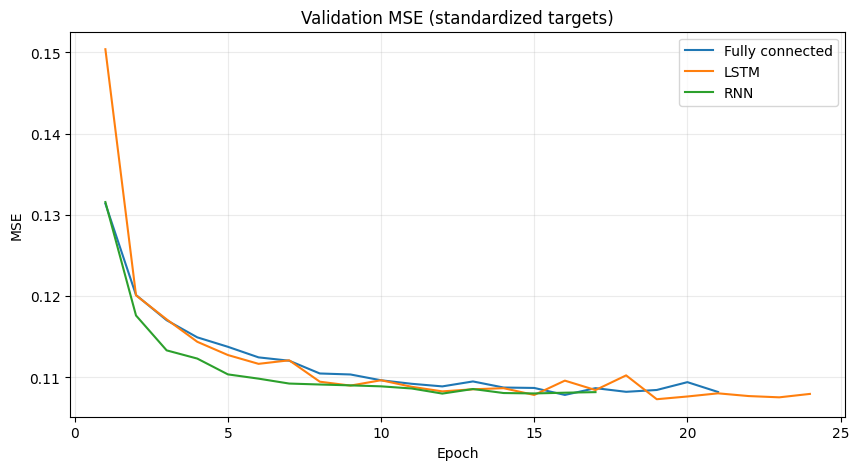

In [11]:
plt.figure(figsize=(10, 5))
for name, h in histories.items():
    plt.plot(range(1, len(h['val_mse']) + 1), h['val_mse'], label=name)
plt.title('Validation MSE (standardized targets)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 8. One-step test evaluation: all four attributes and overall performance

The held-out **2016** test set is evaluated **once after model selection**. We report MAE and RMSE in the original physical units for each of the four attributes. For overall model comparison, we calculate the RMSE on standardized values (so the large numerical scale of atmospheric pressure does not dominate).

A simple *persistence forecast* (use the most recent observed value) is shown as a **reference**, not a fourth trained model required by the assignment.

In [12]:
def predict_normalized(model, loader):
    model.eval()
    chunks = []
    with torch.no_grad():
        for x, _ in loader:
            chunks.append(model(x.to(DEVICE)).cpu().numpy())
    return np.concatenate(chunks, axis=0)


def summarize_errors(truth_raw, pred_raw, model_name):
    err = pred_raw - truth_raw
    standardized_err = err / std
    by_attribute = []
    for j, attr in enumerate(TARGET_COLS):
        by_attribute.append({
            'model': model_name,
            'attribute': attr,
            'MAE': np.mean(np.abs(err[:, j])),
            'RMSE': np.sqrt(np.mean(err[:, j] ** 2)),
        })
    overall = {
        'model': model_name,
        'overall_normalized_MAE': np.mean(np.abs(standardized_err)),
        'overall_normalized_RMSE': np.sqrt(np.mean(standardized_err ** 2)),
    }
    return by_attribute, overall


test_true = splits['test']['y_raw'].astype(np.float64)
predictions = {}
attribute_rows, overall_rows = [], []
for name, model in models.items():
    forecast = predict_normalized(model, test_loader).astype(np.float64) * std + mean
    predictions[name] = forecast
    rows, overall = summarize_errors(test_true, forecast, name)
    attribute_rows.extend(rows)
    overall_rows.append(overall)

persistence = splits['test']['X_raw'][:, -1, :].astype(np.float64)
rows, overall = summarize_errors(test_true, persistence, 'Persistence (reference)')
attribute_rows.extend(rows)
overall_rows.append(overall)

attribute_metrics = pd.DataFrame(attribute_rows)
overall_metrics = pd.DataFrame(overall_rows).sort_values('overall_normalized_RMSE')
print('OVERALL HELD-OUT TEST RESULTS (smaller is better)')
display(overall_metrics.round(4))
print('PER-ATTRIBUTE MAE AND RMSE (original units; smaller is better)')
display(attribute_metrics.pivot(index='model', columns='attribute', values=['MAE', 'RMSE']).round(3))

OVERALL HELD-OUT TEST RESULTS (smaller is better)


,model,overall_normalized_MAE,overall_normalized_RMSE
1,LSTM,0.1635,0.3041
0,Fully connected,0.1655,0.3049
2,RNN,0.1671,0.3065
3,Persistence (reference),0.1872,0.3435


PER-ATTRIBUTE MAE AND RMSE (original units; smaller is better)


MAE                              RMSE           \
attribute               T (degC) p (mbar) rh (%) wv (m/s) T (degC) p (mbar)   
model                                                                         
Fully connected            0.567    0.307  2.518    0.621    0.796    0.402   
LSTM                       0.535    0.300  2.515    0.616    0.761    0.388   
Persistence (reference)    0.696    0.311  3.093    0.676    0.982    0.410   
RNN                        0.546    0.306  2.599    0.627    0.775    0.397   

                                         
attribute               rh (%) wv (m/s)  
model                                    
Fully connected          3.698    0.853  
LSTM                     3.691    0.852  
Persistence (reference)  4.489    0.947  
RNN                      3.762    0.857

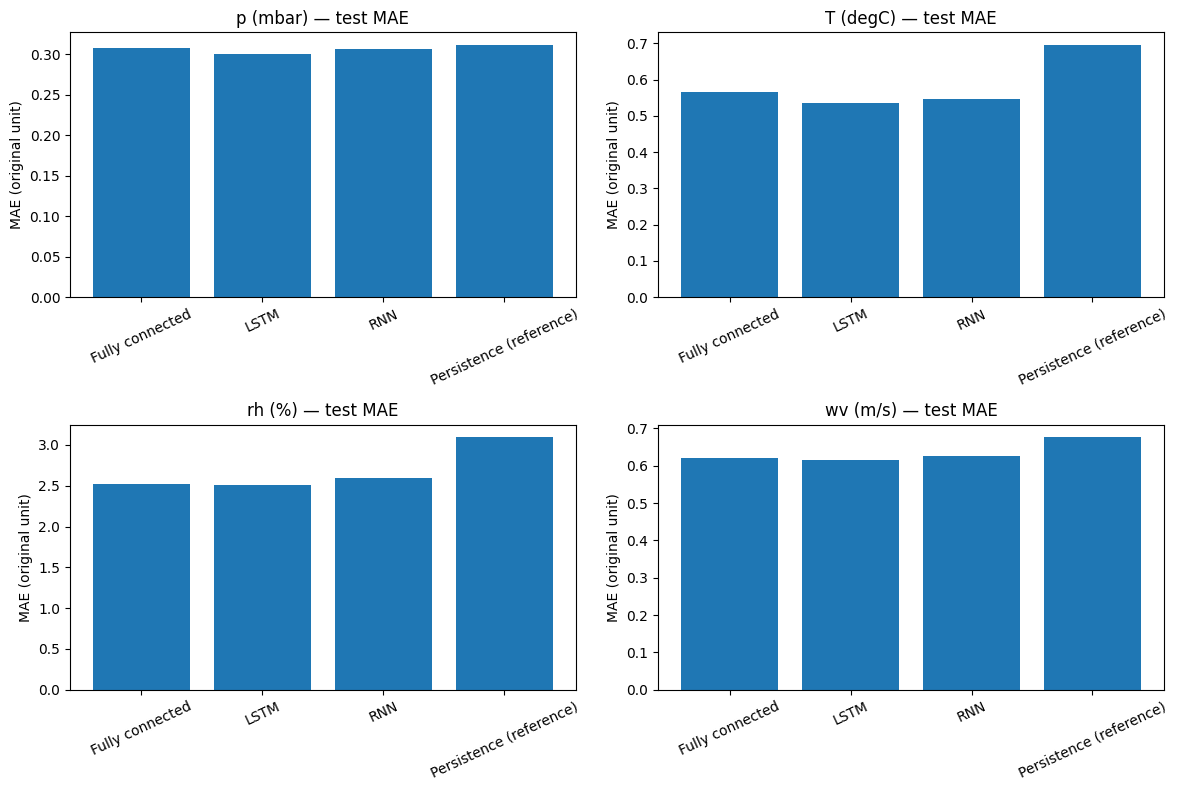

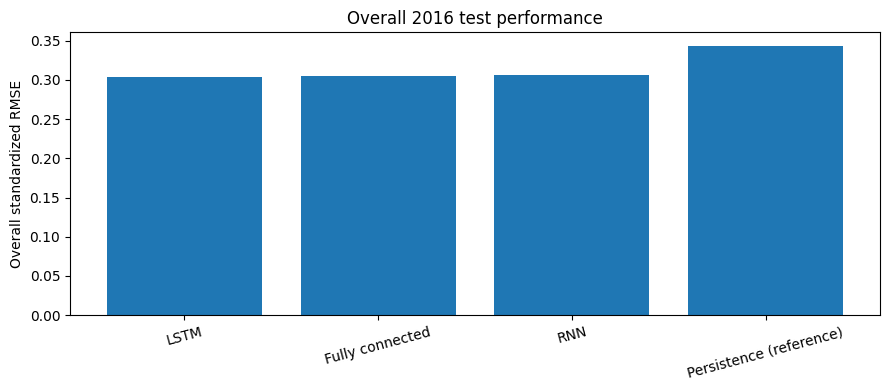

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, attr in zip(axes.flat, TARGET_COLS):
    subset = attribute_metrics[attribute_metrics['attribute'] == attr]
    ax.bar(subset['model'], subset['MAE'])
    ax.set_title(f'{attr} — test MAE')
    ax.set_ylabel('MAE (original unit)')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(overall_metrics['model'], overall_metrics['overall_normalized_RMSE'])
plt.ylabel('Overall standardized RMSE')
plt.title('Overall 2016 test performance')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 9. Recursive 24-hour forecasts and error propagation

At each forecast origin, the models receive **only the previous `K` actual observations**. To predict farther ahead, the last predicted four-variable vector is appended to the history and the oldest input is discarded. No future ground-truth weather features are supplied during recursion.

We use **non-overlapping** forecast origins from the 2016 test period, require the entire context + forecast horizon to be in one continuous time segment, and require observed future labels so that metrics reflect real measurements rather than imputation.

In [14]:
def recursive_origins(horizon=HORIZON, stride=None):
    if stride is None:
        stride = horizon
    if len(df) <= K + horizon:
        raise ValueError('Dataset too short for recursive evaluation.')
    candidates = np.arange(K, len(df) - horizon + 1, stride)
    chosen = []
    for t in candidates:
        if years[t] != 2016 or years[t + horizon - 1] != 2016:
            continue
        if segment[t - K] != segment[t + horizon - 1]:
            continue
        if not valid_input[t - K:t].all() or not observed_target[t:t + horizon].all():
            continue
        chosen.append(t)
    if not chosen:
        raise ValueError('No uninterrupted 2016 test origins for this horizon.')
    origin_indices = np.array(chosen, dtype=int)
    contexts = np.stack([values[t-K:t] for t in origin_indices]).astype(np.float32)
    targets = np.stack([values[t:t+horizon] for t in origin_indices]).astype(np.float64)
    assert np.isfinite(contexts).all() and np.isfinite(targets).all()
    return origin_indices, contexts, targets


def forecast_recursively(model, contexts_raw, horizon=HORIZON):
    # Normalize using training-only statistics; output uses the SAME four variables.
    history = torch.tensor(((contexts_raw - mean) / std).astype(np.float32), device=DEVICE)
    model.eval()
    preds = []
    with torch.no_grad():
        for _ in range(horizon):
            next_step = model(history)       # (number_of_origins, 4)
            preds.append(next_step.cpu().numpy())
            history = torch.cat((history[:, 1:, :], next_step.unsqueeze(1)), dim=1)
    predictions_normalized = np.stack(preds, axis=1)
    return predictions_normalized.astype(np.float64) * std + mean


origin_indices, recursive_contexts, recursive_true = recursive_origins()
recursive_preds = {
    name: forecast_recursively(model, recursive_contexts)
    for name, model in models.items()
}
print(f'Recursive forecast origins: {len(origin_indices):,}; horizon: {HORIZON} hours')
print('Recursive predictions shape:', {k: v.shape for k, v in recursive_preds.items()})

Recursive forecast origins: 361; horizon: 24 hours
Recursive predictions shape: {'Fully connected': (361, 24, 4), 'LSTM': (361, 24, 4), 'RNN': (361, 24, 4)}


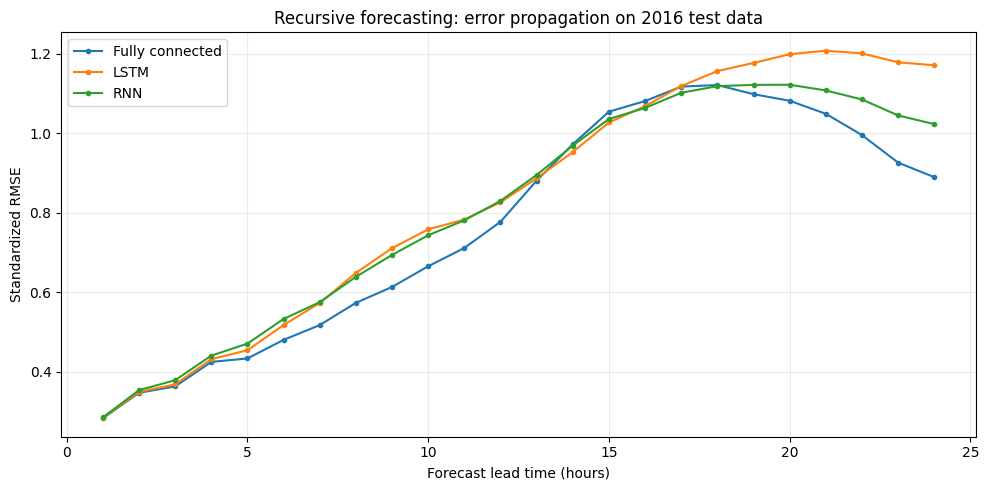

Error propagation summary (smaller is better):


lead_hours,1,6,12,24
model,,,,
Fully connected,0.2827,0.4802,0.7774,0.8898
LSTM,0.2841,0.5176,0.8264,1.1715
RNN,0.2850,0.5329,0.8301,1.0232


In [15]:
# Standardized RMSE at each forecast lead time, aggregated over origins and attributes.
error_curves = {}
for name, pred in recursive_preds.items():
    standardized_error = (pred - recursive_true) / std
    error_curves[name] = np.sqrt(np.mean(standardized_error ** 2, axis=(0, 2)))

plt.figure(figsize=(10, 5))
for name, curve in error_curves.items():
    plt.plot(np.arange(1, HORIZON + 1), curve, marker='.', label=name)
plt.xlabel('Forecast lead time (hours)')
plt.ylabel('Standardized RMSE')
plt.title('Recursive forecasting: error propagation on 2016 test data')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

leads = sorted(set([1, 6, 12, HORIZON]))
propagation_rows = [
    {'model': name, 'lead_hours': lead,
     'normalized_RMSE': curve[lead - 1]}
    for name, curve in error_curves.items()
    for lead in leads if lead <= HORIZON
]
print('Error propagation summary (smaller is better):')
display(pd.DataFrame(propagation_rows)
        .pivot(index='model', columns='lead_hours', values='normalized_RMSE')
        .round(4))

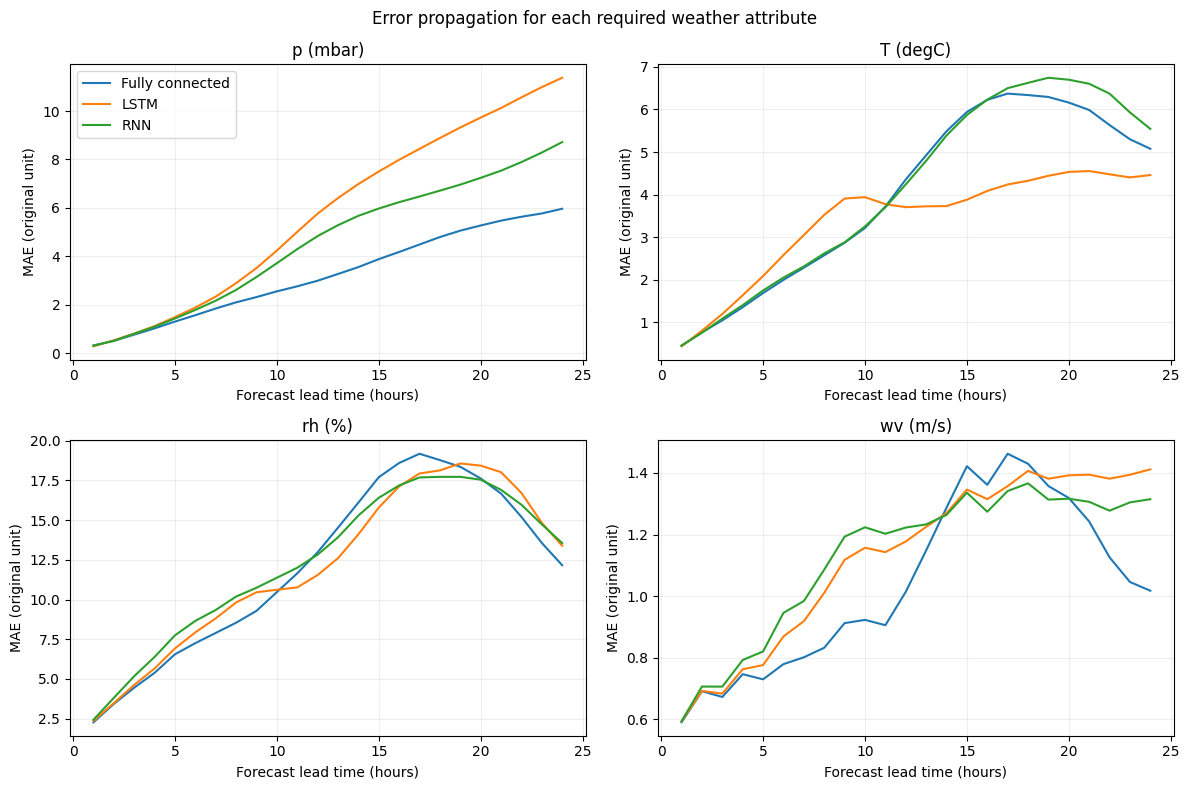

In [16]:
# Separate target-level error propagation (MAE, physical units).
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, (ax, attr) in enumerate(zip(axes.flat, TARGET_COLS)):
    for name, pred in recursive_preds.items():
        mae_by_lead = np.abs(pred[:, :, j] - recursive_true[:, :, j]).mean(axis=0)
        ax.plot(range(1, HORIZON + 1), mae_by_lead, label=name)
    ax.set_title(attr)
    ax.set_xlabel('Forecast lead time (hours)')
    ax.set_ylabel('MAE (original unit)')
    ax.grid(alpha=0.2)
axes[0, 0].legend()
fig.suptitle('Error propagation for each required weather attribute')
plt.tight_layout()
plt.show()

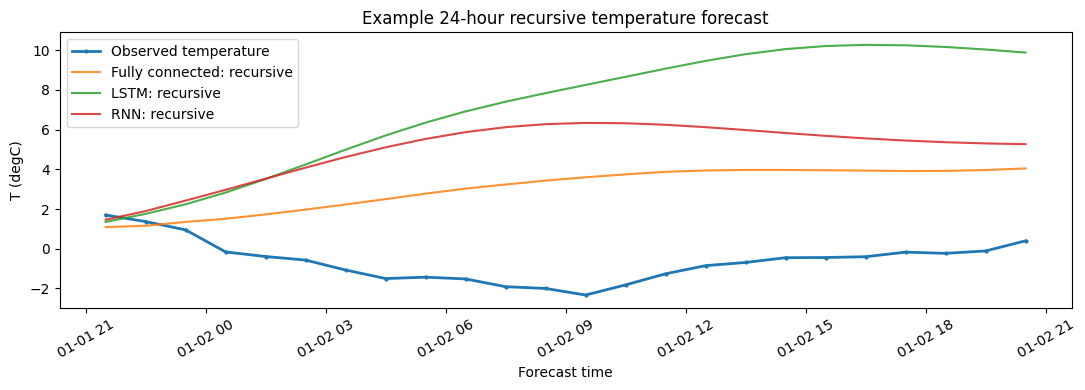

In [17]:
# A concrete example: the first eligible forecast origin, temperature only.
example = 0
when = df.loc[origin_indices[example]:origin_indices[example] + HORIZON - 1, 'Date Time']
plt.figure(figsize=(11, 4))
plt.plot(when, recursive_true[example, :, 1], label='Observed temperature',
         linewidth=2, marker='o', markersize=2)
for name, pred in recursive_preds.items():
    plt.plot(when, pred[example, :, 1], label=f'{name}: recursive', alpha=0.85)
plt.title('Example 24-hour recursive temperature forecast')
plt.xlabel('Forecast time')
plt.ylabel('T (degC)')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 10. Checklist for the written PDF report

**Methods** (assignment page 1):

- **Features:** Four observed weather attributes (`p`, `T`, `rh`, `wv`) over the previous **4** hourly records.
- **Preprocessing:** Sampling, timestamp deduplication, continuity-based window filtering, invalid readings, past-only forward fill for features, training-only mean/std normalization.
- **Models and architecture:** MLP (2 ReLU hidden layers), 2-layer LSTM, 2-layer tanh RNN; all output four real-valued predictions.
- **Loss:** MSE on standardized outputs for all three models.
- **Own model:** vanilla RNN; contrast memory and gating with LSTM, and temporal representations with MLP.
- **Hyperparameters:** `K=4`, `HIDDEN_SIZE=32`, `NUM_LAYERS=2`, Adam `lr=1e-3`, `BATCH_SIZE=256`, `MAX_EPOCHS=25`, patience `5` unless changed in the settings cell.
- **Training:** chronological split, mini-batch updates, early stopping on validation MSE with restoration of best weights.

**Results** (assignment pages 1–2):

- **Metrics:** MAE and RMSE per attribute in original units; overall standardized RMSE and MAE.
- **Comparisons:** Use the one-step performance tables for the four required variables and overall results. Interpret differences rather than only listing numbers.
- **Error propagation:** Use the recursive error curves and table. State explicitly that no future measurements were passed to the model, and discuss how errors change with forecast horizon.

**Submission:** Run the notebook with the **real data**, keep the generated notebook outputs, and submit it together with your **separate written PDF report** inside the required group-named zip. The code notebook is supporting evidence; the PDF report is what the instructions say will be graded.